# Atividade Prática — Análise de Dados de Usuários
Base: `dummyjson.com/users?limit=100`

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://dummyjson.com/users?limit=100"
resposta = requests.get(url)
dados_json = resposta.json()

df_completo = pd.DataFrame(dados_json['users'])

colunas = ['firstName', 'age', 'bloodGroup', 'height', 'weight',
           'eyeColor', 'role', 'university', 'birthDate']
# .copy() evita o SettingWithCopyWarning na célula de tratamento
df = df_completo[colunas].copy()

# TRATAMENTO
df['birthDate'] = pd.to_datetime(df['birthDate'], format="%Y-%m-%d")
print(df.shape)

(100, 9)


## QUESTÃO 1 — Distribuição de Tipos Sanguíneos

            Pessoas     %
bloodGroup               
O-               19  19.0
A+               15  15.0
AB+              13  13.0
AB-              13  13.0
B+               12  12.0
B-               10  10.0
O+               10  10.0
A-                8   8.0
Total: 100


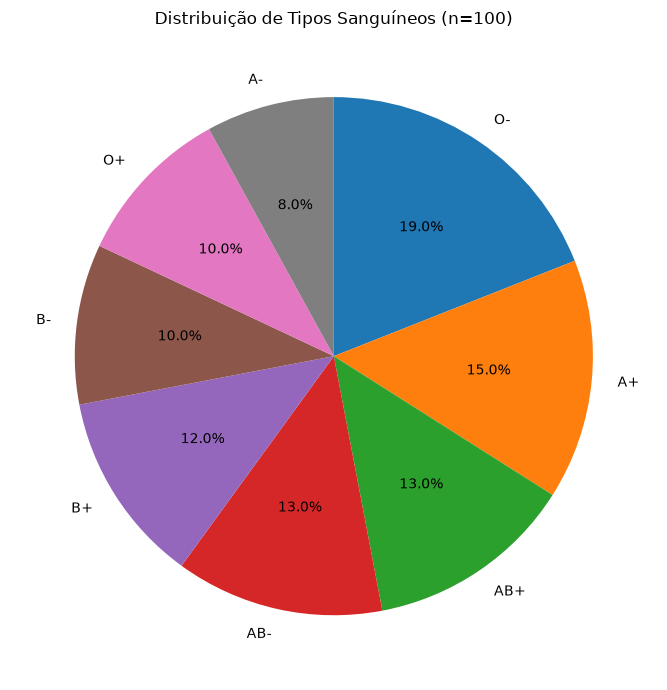

In [2]:
Scontagem = df['bloodGroup'].value_counts()
percentual = (df['bloodGroup'].value_counts(normalize=True) * 100).round(1)
tabela = pd.DataFrame({'Pessoas': contagem, '%': percentual})
print(tabela)
print("Total:", contagem.sum())

plt.figure(figsize=(7, 7))
plt.pie(contagem, labels=contagem.index, autopct='%1.1f%%', startangle=90, counterclock=False)
plt.title('Distribuição de Tipos Sanguíneos (n=100)')
plt.tight_layout()
plt.savefig('q1_tipo_sanguineo.png', dpi=150)
plt.show()

## QUESTÃO 2 — Análise e Filtros de Idade

Abaixo de 30 anos: 34
30 anos ou mais:   66
count    100.0
mean      31.7
std        4.1
min       23.0
25%       28.8
50%       31.0
75%       34.0
max       46.0
Name: age, dtype: float64


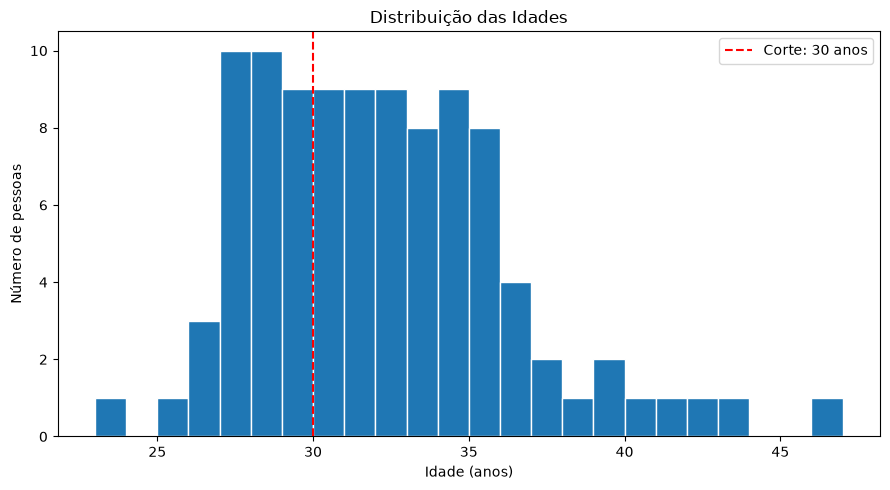

In [3]:
jovens = df[df['age'] < 30]
mais_30 = df[df['age'] >= 30]
print("Abaixo de 30 anos:", len(jovens))
print("30 anos ou mais:  ", len(mais_30))
print(df['age'].describe().round(1))

plt.figure(figsize=(9, 5))
plt.hist(df['age'], bins=range(df['age'].min(), df['age'].max() + 2), edgecolor='white')
plt.axvline(30, color='red', linestyle='--', label='Corte: 30 anos')
plt.title('Distribuição das Idades')
plt.xlabel('Idade (anos)')
plt.ylabel('Número de pessoas')
plt.legend()
plt.tight_layout()
plt.savefig('q2_idades.png', dpi=150)
plt.show()

## QUESTÃO 3 — Cor dos Olhos

eyeColor
Brown     18
Hazel     16
Gray      14
Red       12
Blue      12
Green     11
Amber     10
Violet     7
Name: count, dtype: int64
Mais comum: Brown - 18
Menos comum: Violet - 7


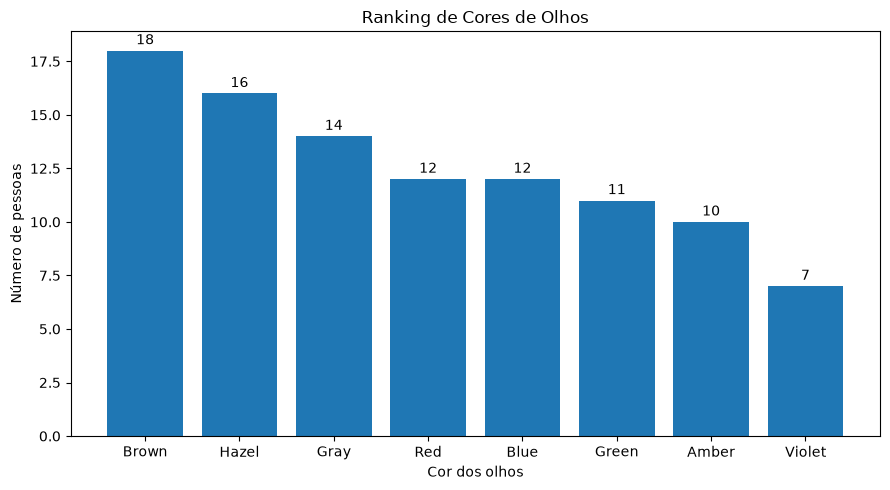

In [4]:
olhos = df['eyeColor'].value_counts()
print(olhos)
print("Mais comum:", olhos.idxmax(), "-", olhos.max())
print("Menos comum:", olhos.idxmin(), "-", olhos.min())

plt.figure(figsize=(9, 5))
plt.bar(olhos.index, olhos.values)
for i, v in enumerate(olhos.values):
    plt.text(i, v + 0.3, str(v), ha='center')
plt.title('Ranking de Cores de Olhos')
plt.xlabel('Cor dos olhos')
plt.ylabel('Número de pessoas')
plt.tight_layout()
plt.savefig('q3_cor_olhos.png', dpi=150)
plt.show()

## QUESTÃO 4 — Relação entre Altura e Peso

Correlação de Pearson (altura x peso): -0.125


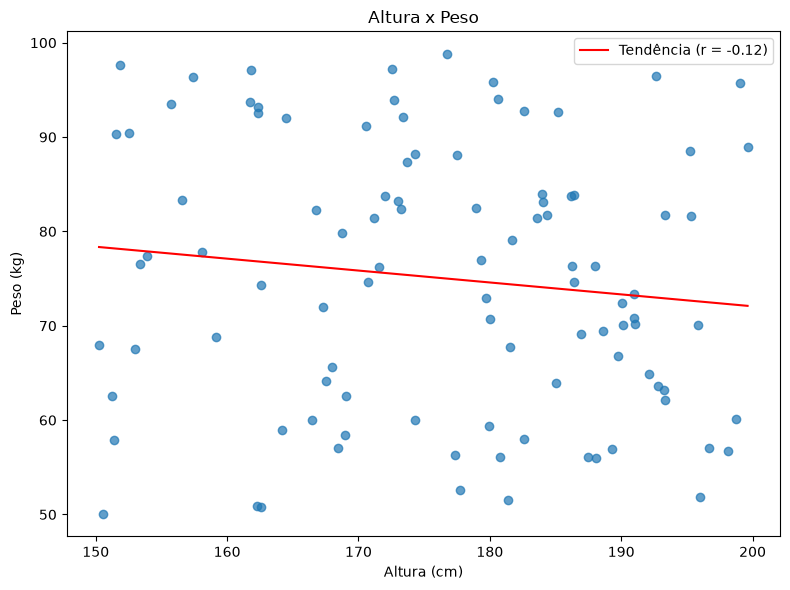

In [5]:
r = df['height'].corr(df['weight'])
print("Correlação de Pearson (altura x peso):", round(r, 3))

plt.figure(figsize=(8, 6))
plt.scatter(df['height'], df['weight'], alpha=0.7)
# linha de tendência (regressão linear simples)
import numpy as np
a, b = np.polyfit(df['height'], df['weight'], 1)
x = np.linspace(df['height'].min(), df['height'].max(), 100)
plt.plot(x, a * x + b, color='red', label=f'Tendência (r = {r:.2f})')
plt.title('Altura x Peso')
plt.xlabel('Altura (cm)')
plt.ylabel('Peso (kg)')
plt.legend()
plt.tight_layout()
plt.savefig('q4_altura_peso.png', dpi=150)
plt.show()

## QUESTÃO 5 — Distribuição de Cargos

role
user         85
moderator    10
admin         5
Name: count, dtype: int64


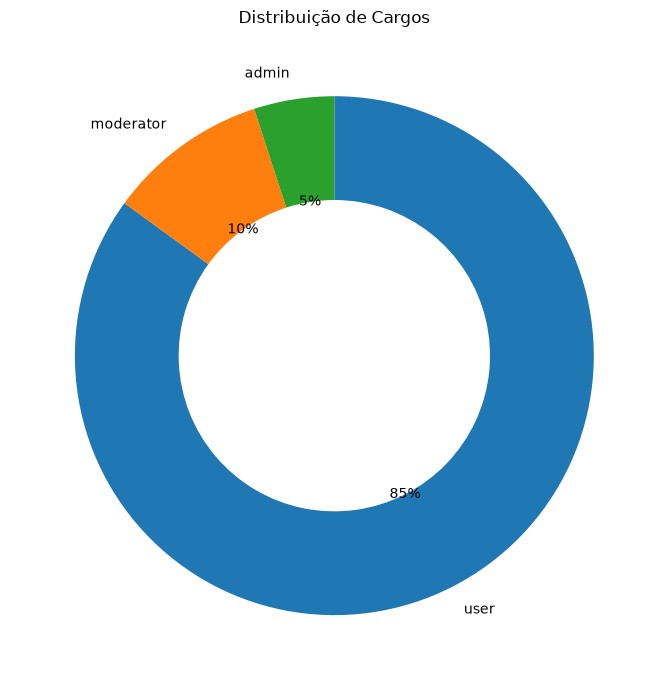

In [6]:
cargos = df['role'].value_counts()
print(cargos)

plt.figure(figsize=(7, 7))
plt.pie(cargos, labels=cargos.index, autopct='%1.0f%%', startangle=90,
        counterclock=False, wedgeprops={'width': 0.4})  # width < 1 = rosca
plt.title('Distribuição de Cargos')
plt.tight_layout()
plt.savefig('q5_cargos.png', dpi=150)
plt.show()

## QUESTÃO 6 — Média de Altura por Cargo

             mean  count
role                    
admin      188.66      5
user       176.35     85
moderator  170.59     10


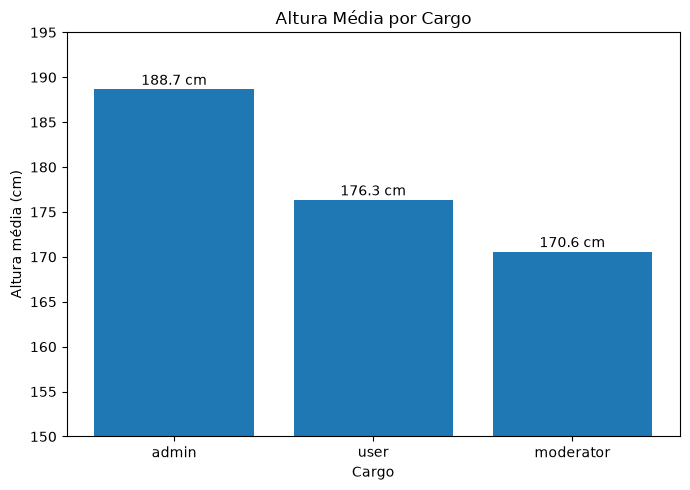

In [7]:
media_altura = df.groupby('role')['height'].agg(['mean', 'count']).round(2)
print(media_altura.sort_values('mean', ascending=False))

m = media_altura['mean'].sort_values(ascending=False)
plt.figure(figsize=(7, 5))
plt.bar(m.index, m.values)
for i, v in enumerate(m.values):
    plt.text(i, v + 0.5, f'{v:.1f} cm', ha='center')
plt.ylim(150, 195)  # eixo cortado: destacar diferença, mas cuidado ao interpretar
plt.title('Altura Média por Cargo')
plt.xlabel('Cargo')
plt.ylabel('Altura média (cm)')
plt.tight_layout()
plt.savefig('q6_altura_cargo.png', dpi=150)
plt.show()

## QUESTÃO 7 — Top 5 Universidades

university
Northeastern University               5
Washington University in St. Louis    5
University of Wisconsin--Madison      4
Ohio State University                 4
Syracuse University                   4
Harvard University                    4
University of Pennsylvania            4
Boston College                        4
Boston University                     4
Yale University                       4
Name: count, dtype: int64

Atenção: quantas universidades têm exatamente 4 usuários? 8


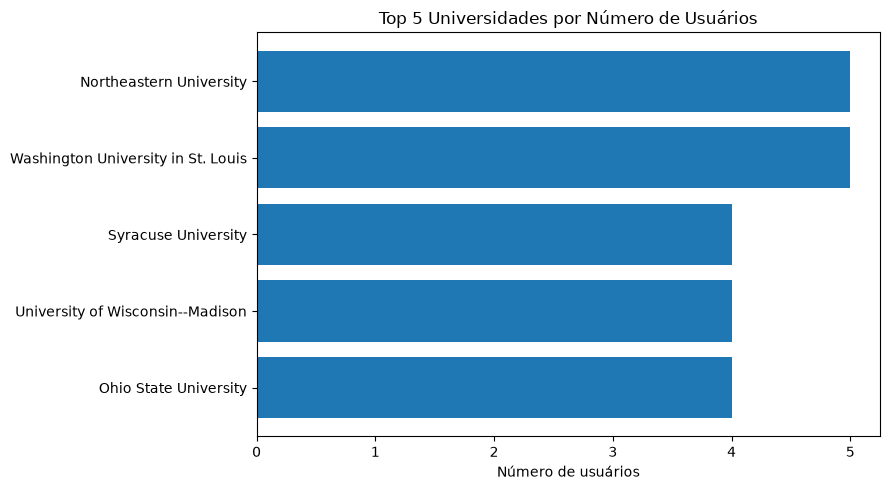

In [8]:
univ = df['university'].value_counts()
print(univ.head(10))
print("\nAtenção: quantas universidades têm exatamente 4 usuários?", (univ == 4).sum())

top5 = univ.head(5).sort_values()
plt.figure(figsize=(9, 5))
plt.barh(top5.index, top5.values)
plt.title('Top 5 Universidades por Número de Usuários')
plt.xlabel('Número de usuários')
plt.tight_layout()
plt.savefig('q7_top5_universidades.png', dpi=150)
plt.show()

## QUESTÃO 8 — Concentração de Peso

count    100.0
mean      75.0
std       14.0
min       50.1
25%       63.0
50%       75.5
75%       87.5
max       98.8
Name: weight, dtype: float64
weight
(50, 60]     21
(60, 70]     17
(70, 80]     21
(80, 90]     20
(90, 100]    21
Name: count, dtype: int64
Outliers (IQR): 0


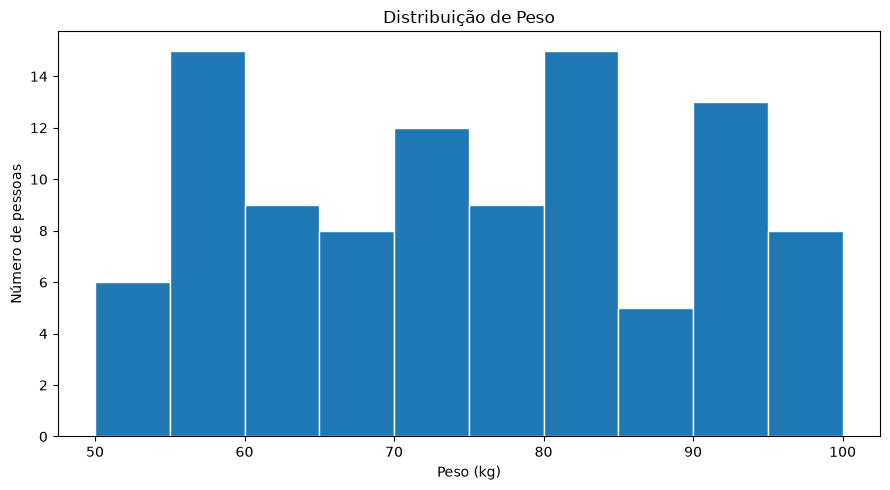

In [9]:
print(df['weight'].describe().round(1))
print(pd.cut(df['weight'], bins=range(50, 101, 10)).value_counts().sort_index())

# outliers pelo critério IQR (1,5 x intervalo interquartil)
q1, q3 = df['weight'].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df['weight'] < q1 - 1.5*iqr) | (df['weight'] > q3 + 1.5*iqr)]
print("Outliers (IQR):", len(outliers))

plt.figure(figsize=(9, 5))
plt.hist(df['weight'], bins=range(50, 101, 5), edgecolor='white')
plt.title('Distribuição de Peso')
plt.xlabel('Peso (kg)')
plt.ylabel('Número de pessoas')
plt.tight_layout()
plt.savefig('q8_peso.png', dpi=150)
plt.show()

## QUESTÃO 9 — Peso > 75 kg E tipo O+

Pesam mais de 75 kg E são O+: 4
Restante da base: 96


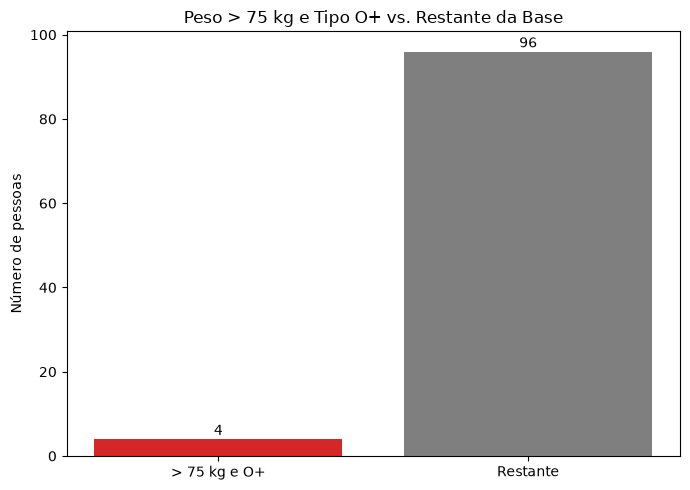

In [10]:
filtro = (df['weight'] > 75) & (df['bloodGroup'] == 'O+')
qtd = filtro.sum()
print("Pesam mais de 75 kg E são O+:", qtd)
print("Restante da base:", len(df) - qtd)

plt.figure(figsize=(7, 5))
plt.bar(['> 75 kg e O+', 'Restante'], [qtd, len(df) - qtd], color=['tab:red', 'tab:gray'])
for i, v in enumerate([qtd, len(df) - qtd]):
    plt.text(i, v + 1, str(v), ha='center')
plt.title('Peso > 75 kg e Tipo O+ vs. Restante da Base')
plt.ylabel('Número de pessoas')
plt.tight_layout()
plt.savefig('q9_cruzamento.png', dpi=150)
plt.show()

## QUESTÃO 10 — Sazonalidade de Nascimentos

birthDate
Jan     4
Fev     9
Mar    10
Abr     9
Mai     7
Jun    14
Jul     5
Ago     8
Set    11
Out     8
Nov     8
Dez     7
Name: count, dtype: int64
Mês com mais aniversariantes: Jun - 14


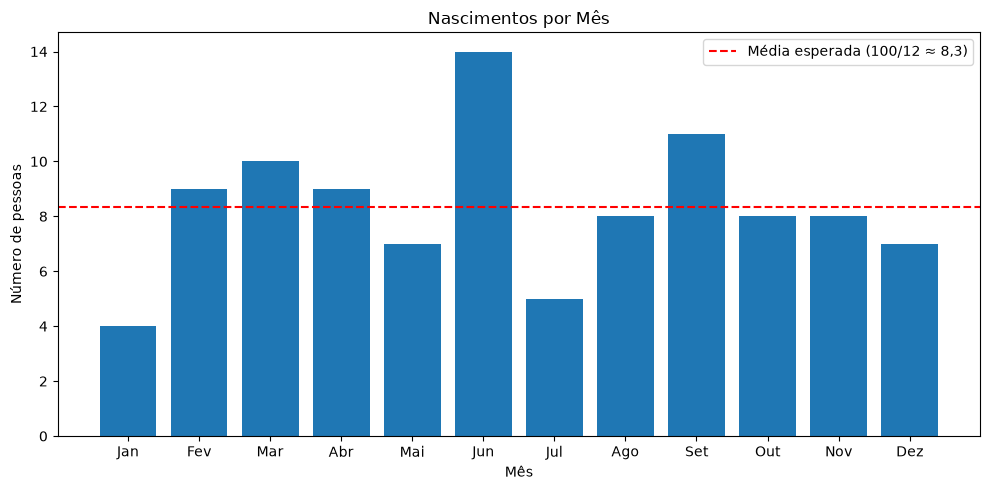

In [11]:
meses = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
por_mes = df['birthDate'].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
print(por_mes.rename(index=dict(zip(range(1, 13), meses))))
print("Mês com mais aniversariantes:", meses[por_mes.idxmax() - 1], "-", por_mes.max())

plt.figure(figsize=(10, 5))
plt.bar(meses, por_mes.values)
plt.axhline(len(df) / 12, color='red', linestyle='--', label='Média esperada (100/12 ≈ 8,3)')
plt.title('Nascimentos por Mês')
plt.xlabel('Mês')
plt.ylabel('Número de pessoas')
plt.legend()
plt.tight_layout()
plt.savefig('q10_nascimentos.png', dpi=150)
plt.show()